In [1]:

from scipy.sparse import load_npz
from pathlib import Path

import pandas as pd
import numpy as np
import re

from sklearn.cluster import DBSCAN

from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity

import joblib
import plotly.express as px
import matplotlib.pyplot as plt

In [2]:
processed_dir = Path("../data/processed")

matrice_tfidf = load_npz(processed_dir / "tfidf_matrix.npz")
ids = pd.read_csv(processed_dir / "tfidf_row_ids.csv")
data = pd.read_csv(processed_dir / "sample_clean.csv")

# Il faut s'assurer que la matrice TF-IDF et les identifiants des lignes correspondent
# bien aux produits du DataFrame original.
assert matrice_tfidf.shape[0] == len(ids)
assert ids["id"].is_unique
assert ids["id"].equals(data["id"])

print("Dimensions :", matrice_tfidf.shape)

Dimensions : (500, 1865)


Le cluster -1 est le cluster considéré comme du bruit par l'algorithme Dbscan. Nous allons tenter de réduire le nombre de produits dans ce cluster en ajustant les paramètres de l'algorithme.

In [3]:
parametres = {
    "eps": [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "min_samples": [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15]
}

resultats = []

for params in ParameterGrid(parametres):
    clusters = DBSCAN(**params, metric="cosine").fit_predict(matrice_tfidf)
    sans_bruit = clusters != -1
    try : 
        score = silhouette_score(
            matrice_tfidf[sans_bruit],
            clusters[sans_bruit],
            metric="cosine"
        )
    except ValueError:
        score = np.nan

    resultats.append({
        **params,
        "silhouette": score,
        "%_bruit": (1 - sans_bruit.mean()) * 100,
        "nb_clusters": len(set(clusters)) - (1 if -1 in clusters else 0)
    })

resultats = pd.DataFrame(resultats)
display(resultats.sort_values("nb_clusters", ascending=False))

,eps,min_samples,silhouette,%_bruit,nb_clusters
22,0.6,2,0.449283,28.6,96
11,0.5,2,0.588570,47.8,86
0,0.4,2,0.745110,62.4,69
33,0.7,2,0.241877,12.0,69
34,0.7,3,0.212389,25.2,36
...,...,...,...,...,...
21,0.5,15,NaN,97.0,1
9,0.4,12,NaN,97.2,1
8,0.4,10,NaN,97.2,1
76,1.0,15,NaN,0.0,1


In [4]:
candidats = resultats[(resultats["nb_clusters"] <= 20) & (resultats["nb_clusters"] >= 10) & resultats["silhouette"].notna()]

In [5]:
display(candidats)

,eps,min_samples,silhouette,%_bruit,nb_clusters
1,0.4,3,0.647273,84.0,15
13,0.5,4,0.482007,78.8,16
24,0.6,4,0.383206,64.0,20
25,0.6,5,0.371570,71.6,12
36,0.7,5,0.217347,44.4,17
37,0.7,6,0.224290,48.4,17
38,0.7,7,0.260460,56.4,14
39,0.7,8,0.261155,62.2,11
44,0.8,2,0.016256,1.0,10


In [6]:
meilleur = candidats.sort_values("silhouette", ascending=False).iloc[0]
display(meilleur)

eps             0.400000
min_samples     3.000000
silhouette      0.647273
%_bruit        84.000000
nb_clusters    15.000000
Name: 1, dtype: float64

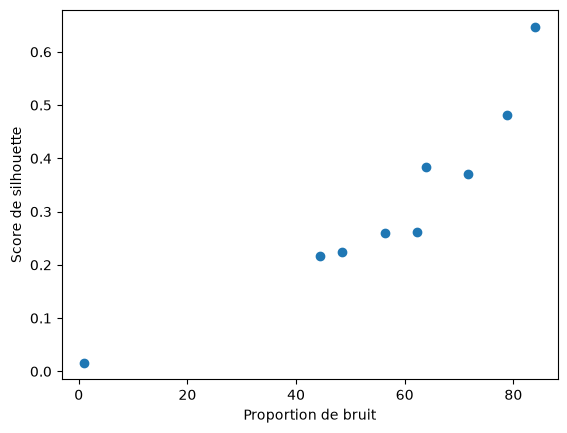

In [7]:
plt.scatter(candidats["%_bruit"], candidats["silhouette"])
plt.xlabel("Proportion de bruit")
plt.ylabel("Score de silhouette")
plt.show()